In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

In [2]:
training_data = datasets.MNIST(root="data", train=True, download=True, transform=ToTensor())
test_data = datasets.MNIST(root="data", train= False, download=True, transform=ToTensor())

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.89MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 153kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.63MB/s]


In [3]:
patch_size = 64
train_dataloader = DataLoader(training_data, batch_size=patch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=patch_size)

for X, y in test_dataloader:
  print("shape of X:", X.shape)
  print("shape of y:", y.shape)
  break

shape of X: torch.Size([64, 1, 28, 28])
shape of y: torch.Size([64])


In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

class NeuralNetwork(nn.Module):
  def __init__(self):
    super().__init__()
    self.flatten = nn.Flatten()
    self.layers = nn.Sequential(
        nn.Linear(28*28, 512), nn.ReLU(),
        nn.Linear(512, 512), nn.ReLU(),
        nn.Linear(512, 10),
    )

  def forward(self, x):
    x = self.flatten(x)
    return self.layers(x)

model = NeuralNetwork().to(device)
print(model)

Using: cpu
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [5]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-2)

In [6]:
def train(dataloader, model, loss_fn, optimizer):
  model.train()
  for batch, (X, y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)
    pred = model(X)
    loss = loss_fn(pred, y)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    if batch % 200 == 0:
       print(f"loss: {loss.item():.4f}  [{batch*len(X)}/{len(dataloader.dataset)}]")

In [7]:
def test(dataloader, model, loss_fn):
    model.eval()
    correct, total_loss = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            total_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).sum().item()
    acc = correct / len(dataloader.dataset)
    print(f"Test accuracy: {acc*100:.1f}%  |  avg loss: {total_loss/len(dataloader):.4f}")
    return acc

In [8]:
epochs = 5
for t in range(epochs):
    print(f"--- Epoch {t+1} ---")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

--- Epoch 1 ---
loss: 2.3153  [0/60000]
loss: 2.1927  [12800/60000]
loss: 1.8760  [25600/60000]
loss: 1.2694  [38400/60000]
loss: 0.6982  [51200/60000]
Test accuracy: 84.6%  |  avg loss: 0.6363
--- Epoch 2 ---
loss: 0.9450  [0/60000]
loss: 0.6057  [12800/60000]
loss: 0.4696  [25600/60000]
loss: 0.2863  [38400/60000]
loss: 0.3688  [51200/60000]
Test accuracy: 89.4%  |  avg loss: 0.3836
--- Epoch 3 ---
loss: 0.3865  [0/60000]
loss: 0.5625  [12800/60000]
loss: 0.1863  [25600/60000]
loss: 0.3896  [38400/60000]
loss: 0.3314  [51200/60000]
Test accuracy: 90.6%  |  avg loss: 0.3277
--- Epoch 4 ---
loss: 0.4055  [0/60000]
loss: 0.1579  [12800/60000]
loss: 0.3308  [25600/60000]
loss: 0.2776  [38400/60000]
loss: 0.3092  [51200/60000]
Test accuracy: 91.6%  |  avg loss: 0.2938
--- Epoch 5 ---
loss: 0.3244  [0/60000]
loss: 0.2020  [12800/60000]
loss: 0.3132  [25600/60000]
loss: 0.3397  [38400/60000]
loss: 0.1614  [51200/60000]
Test accuracy: 92.2%  |  avg loss: 0.2725


In [9]:
def fgsm_attack(images, epsilon, grads):
    perturbed = images + epsilon * grads.sign()
    perturbed = torch.clamp(perturbed, 0, 1)
    return perturbed

In [10]:
def test_attack(model, dataloader, epsilon):
    model.eval()
    correct = 0
    examples = []
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        X.requires_grad = True
        pred = model(X)
        loss = loss_fn(pred, y)
        model.zero_grad()
        loss.backward()
        X_adv = fgsm_attack(X, epsilon, X.grad)
        with torch.no_grad():
            adv_pred = model(X_adv).argmax(1)
        correct += (adv_pred == y).sum().item()
        for i in range(len(y)):
            if len(examples) < 5 and adv_pred[i] != y[i]:
                examples.append((y[i].item(), adv_pred[i].item(), X_adv[i].detach().cpu().squeeze().numpy()))
    acc = correct / len(dataloader.dataset)
    print(f"Epsilon: {epsilon}  |  Accuracy under attack: {acc*100:.1f}%")
    return acc, examples

In [11]:
epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
accuracies = []
all_examples = []
for eps in epsilons:
    acc, ex = test_attack(model, test_dataloader, eps)
    accuracies.append(acc)
    all_examples.append(ex)

Epsilon: 0  |  Accuracy under attack: 92.2%
Epsilon: 0.05  |  Accuracy under attack: 72.9%
Epsilon: 0.1  |  Accuracy under attack: 33.6%
Epsilon: 0.15  |  Accuracy under attack: 8.6%
Epsilon: 0.2  |  Accuracy under attack: 1.2%
Epsilon: 0.25  |  Accuracy under attack: 0.1%
Epsilon: 0.3  |  Accuracy under attack: 0.0%


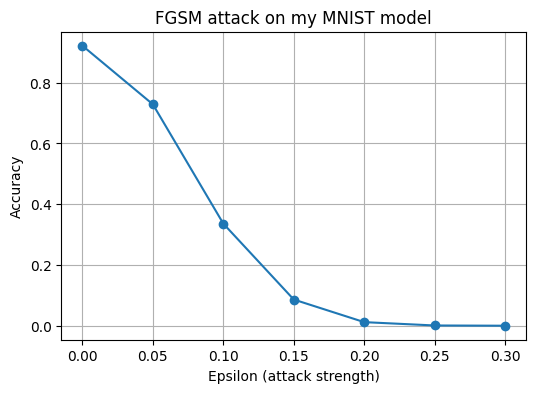

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(epsilons, accuracies, "o-")
plt.xlabel("Epsilon (attack strength)")
plt.ylabel("Accuracy")
plt.title("FGSM attack on my MNIST model")
plt.grid(True)
plt.show()

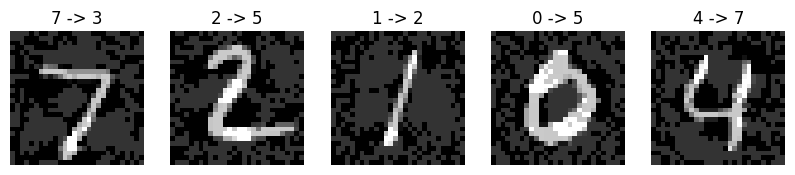

In [13]:
ex = all_examples[4]
plt.figure(figsize=(10, 2.5))
for i, (orig, adv, img) in enumerate(ex):
    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(f"{orig} -> {adv}")
    plt.axis("off")
plt.show()
